<a href="https://colab.research.google.com/github/pedrodamiaoluz/sentiment-analysis-tweets/blob/main/LSTMs/sentiment140_tweets_LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Importando as Bibliotecas

In [ ]:
import kagglehub
import pandas as pd
import re
import os
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, BatchNormalization
from sklearn.metrics import classification_report

## Link do Dataset: [https://www.kaggle.com/datasets/kazanova/sentiment140](https://www.kaggle.com/datasets/kazanova/sentiment140)

## 1. Configurações e Hiperparâmetros

In [ ]:
vocab_size = 20000
max_length = 100
batch_size = 32
epochs = 5

## 2. Carregamento e Preparação dos Dados

In [ ]:
path = kagglehub.dataset_download("kazanova/sentiment140")
print("Path to dataset files:", path)

caminho_arquivo = os.path.join(path, 'training.1600000.processed.noemoticon.csv')

colunas = ['target', 'id', 'date', 'flag', 'user', 'text']
df = pd.read_csv(caminho_arquivo, encoding='latin-1', names=colunas)

100%|██████████| 80.9M/80.9M [00:01<00:00, 58.5MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/kazanova/sentiment140/versions/2


### Manter apenas as colunas relevantes

In [ ]:
df = df[['text', 'target']]
df['target'] = df['target'].replace(4, 1)
df = df.dropna(subset=['target'])

tamanho_amostra_por_classe = 25000
df_negativo = df[df['target'] == 0].sample(n=tamanho_amostra_por_classe, random_state=42)
df_positivo = df[df['target'] == 1].sample(n=tamanho_amostra_por_classe, random_state=42)

df = pd.concat([df_negativo, df_positivo]).sample(frac=1, random_state=42).reset_index(drop=True)
print(f"Novo tamanho do dataset: {len(df)} registros ({tamanho_amostra_por_classe} de cada classe).")

Novo tamanho do dataset: 50000 registros (25000 de cada classe).


In [ ]:
def limpar_texto(texto):
    texto = re.sub(r'@\w+', '', texto)
    texto = re.sub(r'http\S+', '', texto)
    texto = re.sub(r'[^a-zA-Z\s]', '', texto)
    return texto.lower().strip()


df['text'] = df['text'].apply(limpar_texto)

## 3. Tokenização e Preenchimento (Padding)

In [ ]:
# Divisão em treino e teste (80% treino, 20% teste)
X_train, X_test, y_train, y_test = train_test_split(df['text'], df['target'], test_size=0.2, random_state=42)

tokenizer = Tokenizer(num_words=vocab_size)
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(X_train_seq, maxlen=max_length, padding='pre')
X_test_pad = pad_sequences(X_test_seq, maxlen=max_length, padding='pre')

## 4. Arquitetura do Modelo LSTM

In [ ]:
modelo = Sequential()
modelo.add(Embedding(input_dim=vocab_size, output_dim=128))

modelo.add(LSTM(units=128, return_sequences=True))
modelo.add(Dropout(0.2))

modelo.add(LSTM(units=64, return_sequences=True))
modelo.add(Dropout(0.2))

modelo.add(LSTM(units=64, return_sequences=False))
modelo.add(Dropout(0.2))

modelo.add(Dense(1, activation='sigmoid'))

## 5. Compilando o modelo para classificação multiclasse

In [ ]:
modelo.compile(
    loss='binary_crossentropy',
    optimizer=Adam(learning_rate=0.0001),
    metrics=['accuracy']
)

modelo.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## 6. Treinamento do modelo

In [ ]:
historico = modelo.fit(
    X_train_pad, y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_data=(X_test_pad, y_test)
)

Epoch 1/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 29s 21ms/step - accuracy: 0.6617 - loss: 0.6036 - val_accuracy: 0.7363 - val_loss: 0.5276
Epoch 2/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 25s 20ms/step - accuracy: 0.7839 - loss: 0.4649 - val_accuracy: 0.7604 - val_loss: 0.4947
Epoch 3/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 42s 21ms/step - accuracy: 0.8177 - loss: 0.4090 - val_accuracy: 0.7689 - val_loss: 0.4930
Epoch 4/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 25s 20ms/step - accuracy: 0.8404 - loss: 0.3697 - val_accuracy: 0.7695 - val_loss: 0.5031
Epoch 5/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 25s 20ms/step - accuracy: 0.8546 - loss: 0.3422 - val_accuracy: 0.7612 - val_loss: 0.5466


## 7. Visualização das Predições

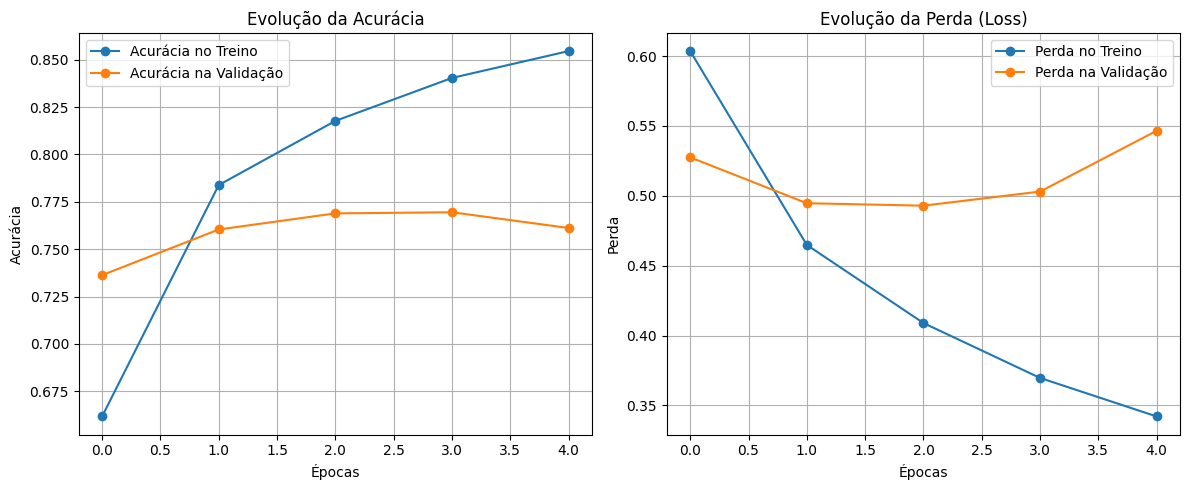

In [ ]:
plt.figure(figsize=(12, 5))

# Gráfico de Acurácia
plt.subplot(1, 2, 1)
plt.plot(historico.history['accuracy'], label='Acurácia no Treino', marker='o')
plt.plot(historico.history['val_accuracy'], label='Acurácia na Validação', marker='o')
plt.title('Evolução da Acurácia')
plt.xlabel('Épocas')
plt.ylabel('Acurácia')
plt.legend()
plt.grid(True)

# Gráfico de Perda (Loss)
plt.subplot(1, 2, 2)
plt.plot(historico.history['loss'], label='Perda no Treino', marker='o')
plt.plot(historico.history['val_loss'], label='Perda na Validação', marker='o')
plt.title('Evolução da Perda (Loss)')
plt.xlabel('Épocas')
plt.ylabel('Perda')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## 8. Avaliação do modelo

In [ ]:
y_pred_prob = modelo.predict(X_test_pad)
y_pred = (y_pred_prob > 0.5).astype(int).flatten()

y_true = y_test

class_names = ['Negativo', 'Positivo']

relatorio = classification_report(y_true, y_pred, target_names=class_names, zero_division=0)
print("Relatório de Classificação:\n")
print(relatorio)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step
Relatório de Classificação:

              precision    recall  f1-score   support

    Negativo       0.76      0.76      0.76      5028
    Positivo       0.76      0.76      0.76      4972

    accuracy                           0.76     10000
   macro avg       0.76      0.76      0.76     10000
weighted avg       0.76      0.76      0.76     10000

